# Northern Virginia (NOVA) — Population Demographics Analysis
**Prepared by:** Parity Insights LLC | **Purpose:** Retail Site Selection & Customer Profiling

---

## Research Questions

1. What are the gender and age dynamics across NOVA counties — who is the primary customer profile?
2. What are the income dynamics by age group across each county?
3. What is the language diversity landscape, and what are the implications for marketing strategy?

---

**Data:** U.S. Census Bureau, American Community Survey (ACS) 1-Year Estimates, 2025
**Counties:** Arlington, Fairfax, Fauquier, Loudoun, Prince William

In [ ]:
# Standard data analysis and visualization libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Section 1 — Female Population Demographics by Age Group

**Objective:** Identify the size and age distribution of the primary target demographic (females, ages 20–59) across NOVA counties.

**Source:** ACS Table S0101 — Age and Sex (1-Year Estimates, 2025)

In [ ]:
# Load ACS S0101 population data; first data row contains descriptive column labels
population_nova = pd.read_csv("/content/ACSST1Y2025.S0101-Data.csv")

# Promote first row to column headers (ACS CSV format includes a label row)
population_nova.columns = population_nova.iloc[0]

# Drop margin-of-error columns — analysis uses point estimates only
population_nova = population_nova.loc[
    :, ~population_nova.columns.str.startswith("Margin of Error", na=False)
]

population_nova.head()

In [ ]:
# Inspect all available column names after cleaning
population_nova.columns.tolist()

In [ ]:
# Target demographic: females aged 20–59 (primary retail customer profile)
target_columns = [
    "Estimate!!Total!!Total population",
    "Estimate!!Percent Female!!Total population!!AGE!!20 to 24 years",
    "Estimate!!Percent Female!!Total population!!AGE!!25 to 29 years",
    "Estimate!!Percent Female!!Total population!!AGE!!30 to 34 years",
    "Estimate!!Percent Female!!Total population!!AGE!!35 to 39 years",
    "Estimate!!Percent Female!!Total population!!AGE!!40 to 44 years",
    "Estimate!!Percent Female!!Total population!!AGE!!45 to 49 years",
    "Estimate!!Percent Female!!Total population!!AGE!!50 to 54 years",
    "Estimate!!Percent Female!!Total population!!AGE!!55 to 59 years",
]

nova_target_females = population_nova[target_columns].copy()
nova_target_females

In [ ]:
# -----------------------------------------------------------------
# 1. Column definitions — include county name for downstream filters
# -----------------------------------------------------------------
geo_col = "Geographic Area Name"
total_pop_col = "Estimate!!Total!!Total population"

pct_age_columns = [
    "Estimate!!Percent Female!!Total population!!AGE!!20 to 24 years",
    "Estimate!!Percent Female!!Total population!!AGE!!25 to 29 years",
    "Estimate!!Percent Female!!Total population!!AGE!!30 to 34 years",
    "Estimate!!Percent Female!!Total population!!AGE!!35 to 39 years",
    "Estimate!!Percent Female!!Total population!!AGE!!40 to 44 years",
    "Estimate!!Percent Female!!Total population!!AGE!!45 to 49 years",
    "Estimate!!Percent Female!!Total population!!AGE!!50 to 54 years",
    "Estimate!!Percent Female!!Total population!!AGE!!55 to 59 years",
]

nova_target_females = population_nova[[geo_col, total_pop_col] + pct_age_columns].copy()

# -----------------------------------------------------------------
# 2. Convert demographic values to numeric
# -----------------------------------------------------------------
nova_target_females[total_pop_col] = pd.to_numeric(
    nova_target_females[total_pop_col], errors="coerce"
)
nova_target_females[pct_age_columns] = nova_target_females[pct_age_columns].apply(
    pd.to_numeric, errors="coerce"
)

# -----------------------------------------------------------------
# 3. Derive headcount columns from percentage × total population
# -----------------------------------------------------------------
count_columns = [col.replace("Percent Female", "Count Female") for col in pct_age_columns]

for pct_col, count_col in zip(pct_age_columns, count_columns):
    nova_target_females[count_col] = (
        (nova_target_females[pct_col] / 100.0) * nova_target_females[total_pop_col]
    ).round()

# -----------------------------------------------------------------
# 4. Arlington County — target female age distribution
# -----------------------------------------------------------------
arlington = nova_target_females[
    nova_target_females[geo_col].str.contains("Arlington", case=False, na=False)
]

values = arlington[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nArlington County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [ ]:
# Fairfax County — target female age distribution
fairfax = nova_target_females[
    nova_target_females[geo_col].str.contains("Fairfax", case=False, na=False)
]

values = fairfax[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nFairfax County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [ ]:
# Prince William County — target female age distribution
prince_william = nova_target_females[
    nova_target_females[geo_col].str.contains("Prince William", case=False, na=False)
]

values = prince_william[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nPrince William County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [ ]:
# Fauquier County — target female age distribution
fauquier = nova_target_females[
    nova_target_females[geo_col].str.contains("Fauquier", case=False, na=False)
]

values = fauquier[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nFauquier County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

## Section 2 — Median Household Income by Age Group

**Objective:** Validate purchasing power across householder age cohorts in each NOVA county to confirm market viability.

**Source:** ACS Table S1903 — Median Income in the Past 12 Months (1-Year Estimates, 2025)

In [ ]:
# Load ACS S1903 income data
income_nova = pd.read_csv("/content/income.S1903-Data.csv")
income_nova

In [ ]:
# Promote first row to column headers; drop all margin-of-error columns
income_nova.columns = income_nova.iloc[0]

nova_income_cleaned = (
    income_nova.iloc[1:]
    .loc[:, ~income_nova.columns.str.startswith("Margin of Error", na=False)]
    .reset_index(drop=True)
)

nova_income_cleaned.head()

In [ ]:
# Inspect available column names to identify income target columns
nova_income_cleaned.columns.to_list()

# Target: median income by householder age group covering the primary spend cohorts
target_income_columns = [
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!15 to 24 years",
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!25 to 44 years",
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!45 to 64 years",
]

In [ ]:
# Build target income DataFrame with county identifier
county_location = "Geographic Area Name"

nova_income_target = nova_income_cleaned[[county_location] + target_income_columns].copy()

# Convert income values to numeric; strip commas from formatted strings
for col in target_income_columns:
    nova_income_target[col] = pd.to_numeric(
        nova_income_target[col].astype(str).str.replace(",", ""), errors="coerce"
    )

nova_income_target.head()

In [ ]:
# Reshape to long format for bubble chart visualization
df_plot_income = nova_income_target.copy()

# Shorten county names for axis legibility
df_plot_income["Region"] = (
    df_plot_income["Geographic Area Name"]
    .str.replace("County, Virginia", "", regex=False)
    .str.replace(", Virginia", "", regex=False)
    .str.strip()
)

df_income_long = pd.melt(
    df_plot_income,
    id_vars=["Region"],
    value_vars=target_income_columns,
    var_name="Age Group",
    value_name="Median Income",
)

# Simplify age group labels (e.g. "25 to 44 years")
df_income_long["Age Group"] = df_income_long["Age Group"].apply(
    lambda x: x.split("!!")[-1].replace(" years", "")
)

df_income_long["Median Income"] = pd.to_numeric(
    df_income_long["Median Income"], errors="coerce"
)

df_income_long.head()

In [ ]:
# Bubble matrix: county × age group, sized and colored by median income
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)

sns.scatterplot(
    data=df_income_long,
    x="Region",
    y="Age Group",
    size="Median Income",
    hue="Median Income",
    palette="viridis",
    sizes=(600, 3200),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.88,
    ax=ax,
)

# Annotate each bubble with the exact dollar value
for _, row in df_income_long.iterrows():
    if pd.notna(row["Median Income"]):
        ax.text(
            x=row["Region"],
            y=row["Age Group"],
            s=f"${int(row['Median Income']):,}",
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color="black",
        )

plt.title(
    "Northern Virginia — Median Household Income by County & Age Group",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("County / Jurisdiction", fontweight="bold", labelpad=10)
plt.ylabel("Householder Age Group", fontweight="bold", labelpad=10)
ax.set_ylim(-0.5, 2.5)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    title="Median Income ($)",
)

plt.tight_layout()
plt.show()

### Section 2 — Key Findings: Median Household Income

NOVA is consistently among the highest-income regions in the United States. All five counties show strong purchasing power across all age groups.

| County | 15–24 | 25–44 | 45–64 |
|---|---|---|---|
| Arlington | $70,967 | $126,988 | $203,754 |
| Fairfax | $71,756 | $161,948 | $189,772 |
| Fauquier | $118,590 | $136,034 | $187,075 |
| Loudoun | $52,997 | $205,596 | $215,139 |
| Prince William | $87,145 | $145,367 | $168,086 |

**Key observations:**
- The **45–64 cohort** holds the highest incomes in every county, peaking in Loudoun ($215K) and Arlington ($204K).
- The **25–44 cohort** — the core target segment — is strongest in Loudoun ($206K) and Fairfax ($162K).
- **Fauquier** shows surprisingly strong 15–24 income ($119K), likely reflecting small sample sizes in a low-density county.

**Recommendation:** Fairfax County presents the optimal balance of target population scale and purchasing power. Loudoun, while income-leading in the 25–44 bracket, is geographically dispersed with lower retail foot-traffic density and longer commute distances — factors that reduce walk-in viability. Fairfax offers depth of market, dense commercial corridors, and the second-highest income among the primary target age group.

## Section 3 — Spoken Language Demographics

**Objective:** Map language diversity across NOVA counties to inform multilingual marketing strategy and in-store experience planning.

**Source:** ACS Table S1602 — Language Spoken at Home (1-Year Estimates, 2025)

In [ ]:
# Load ACS S1602 language data
spoken_language_df = pd.read_csv("/content/spoken_language.S1602-Data.csv")
spoken_language_df

In [ ]:
# Promote first row to column headers; drop all margin-of-error columns
spoken_language_df.columns = spoken_language_df.iloc[0]

cleaned_spoken_language_df = (
    spoken_language_df.iloc[1:]
    .loc[:, ~spoken_language_df.columns.str.startswith("Margin of Error", na=False)]
    .reset_index(drop=True)
)

cleaned_spoken_language_df

In [ ]:
# Inspect available column names
cleaned_spoken_language_df.columns.to_list()

# Target: household counts by primary non-English language group
speaking_language = [
    "Estimate!!Total!!All households!!Households speaking --!!Spanish",
    "Estimate!!Total!!All households!!Households speaking --!!Other Indo-European languages",
    "Estimate!!Total!!All households!!Households speaking --!!Asian and Pacific Island languages",
    "Estimate!!Total!!All households!!Households speaking --!!Other languages",
]

In [ ]:
# Build speaking language DataFrame; reuse county_location variable from Section 2
speaking_language_target = cleaned_spoken_language_df[
    [county_location] + speaking_language
].copy()

# Convert household counts to numeric
for col in speaking_language:
    speaking_language_target[col] = pd.to_numeric(
        speaking_language_target[col].astype(str).str.replace(",", ""), errors="coerce"
    )

speaking_language_target

In [ ]:
# Reshape to long format for bubble chart visualization
df_speaking_language = speaking_language_target.copy()

# Shorten county names for axis legibility
df_speaking_language["Region"] = (
    df_speaking_language["Geographic Area Name"]
    .str.replace("County, Virginia", "", regex=False)
    .str.replace(", Virginia", "", regex=False)
    .str.strip()
)

df_language_long = pd.melt(
    df_speaking_language,
    id_vars=["Region"],
    value_vars=speaking_language,
    var_name="Language Group",
    value_name="Households",
)

# Simplify language labels to the final segment (e.g. "Spanish")
df_language_long["Language Group"] = df_language_long["Language Group"].apply(
    lambda x: x.split("!!")[-1]
)

df_language_long["Households"] = pd.to_numeric(
    df_language_long["Households"], errors="coerce"
)

df_language_long

In [ ]:
# Bubble matrix: county × language group, sized and colored by household count
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)

sns.scatterplot(
    data=df_language_long,
    x="Region",
    y="Language Group",
    size="Households",
    hue="Households",
    palette="viridis",
    sizes=(600, 3200),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.88,
    ax=ax,
)

# Annotate each bubble with the exact household count
for _, row in df_language_long.iterrows():
    if pd.notna(row["Households"]):
        ax.text(
            x=row["Region"],
            y=row["Language Group"],
            s=f"{int(row['Households']):,}",
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color="black",
        )

plt.title(
    "Northern Virginia — Non-English Speaking Households by County & Language Group",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("County / Jurisdiction", fontweight="bold", labelpad=10)
plt.ylabel("Language Group", fontweight="bold", labelpad=10)
ax.set_ylim(-0.5, 3.5)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    title="Households",
)

plt.tight_layout()
plt.show()

### Section 3 — Key Findings: Language Diversity

NOVA's population is markedly multilingual, with direct implications for marketing reach and in-store experience strategy.

| County | Spanish | Other Indo-European | Asian / Pacific Island | Other |
|---|---|---|---|---|
| Arlington | 12,733 | 11,786 | 6,903 | 5,886 |
| Fairfax | 53,066 | 43,217 | 60,213 | 19,226 |
| Fauquier | N/A | N/A | N/A | N/A |
| Loudoun | 16,040 | 21,726 | 18,363 | 4,231 |
| Prince William | 32,644 | 13,235 | 10,563 | 10,851 |

*Fauquier County data suppressed by Census Bureau due to small sample size.*

**Key observations:**
- **Fairfax** has the highest absolute non-English speaking household count across every language group — notably ~60K Asian/Pacific Island-language households and ~53K Spanish-speaking households.
- **Prince William** has a large Spanish-speaking population (~33K), indicating a significant Hispanic/Latino community that warrants targeted outreach.
- **Arlington** shows high proportional linguistic diversity relative to its total household count (~37K of ~114K households speak a non-English language at home).

**Marketing implication:** Any location in Fairfax or Prince William County should incorporate multilingual customer communication — at minimum in Spanish, and ideally with support for common Asian languages — to capture the full addressable market.

---

## Overall Summary & Site Recommendation

Across all three dimensions of analysis — female demographic depth, household income, and language diversity — **Fairfax County** consistently emerges as the optimal market for expansion.

| Dimension | Fairfax | Arlington | Prince William | Loudoun |
|---|---|---|---|---|
| Target female headcount (20–59) | **Highest** | High | High | High |
| Median income — 25–44 cohort | $161,948 | $126,988 | $145,367 | $205,596 |
| Retail density / foot traffic | **High** | High | Medium | Low |
| Non-English speaking households | **~176K** | ~37K | ~67K | ~60K |

**Final recommendation: Fairfax County** provides the deepest addressable market, strongest commercial infrastructure, and second-highest income in the primary 25–44 cohort. Loudoun County, while income-leading, is eliminated on geographic and commute grounds. Arlington, while viable, offers a fraction of Fairfax's total market scale.

*Analysis prepared by Parity Insights LLC — all data sourced from U.S. Census Bureau ACS 1-Year Estimates, 2025.*

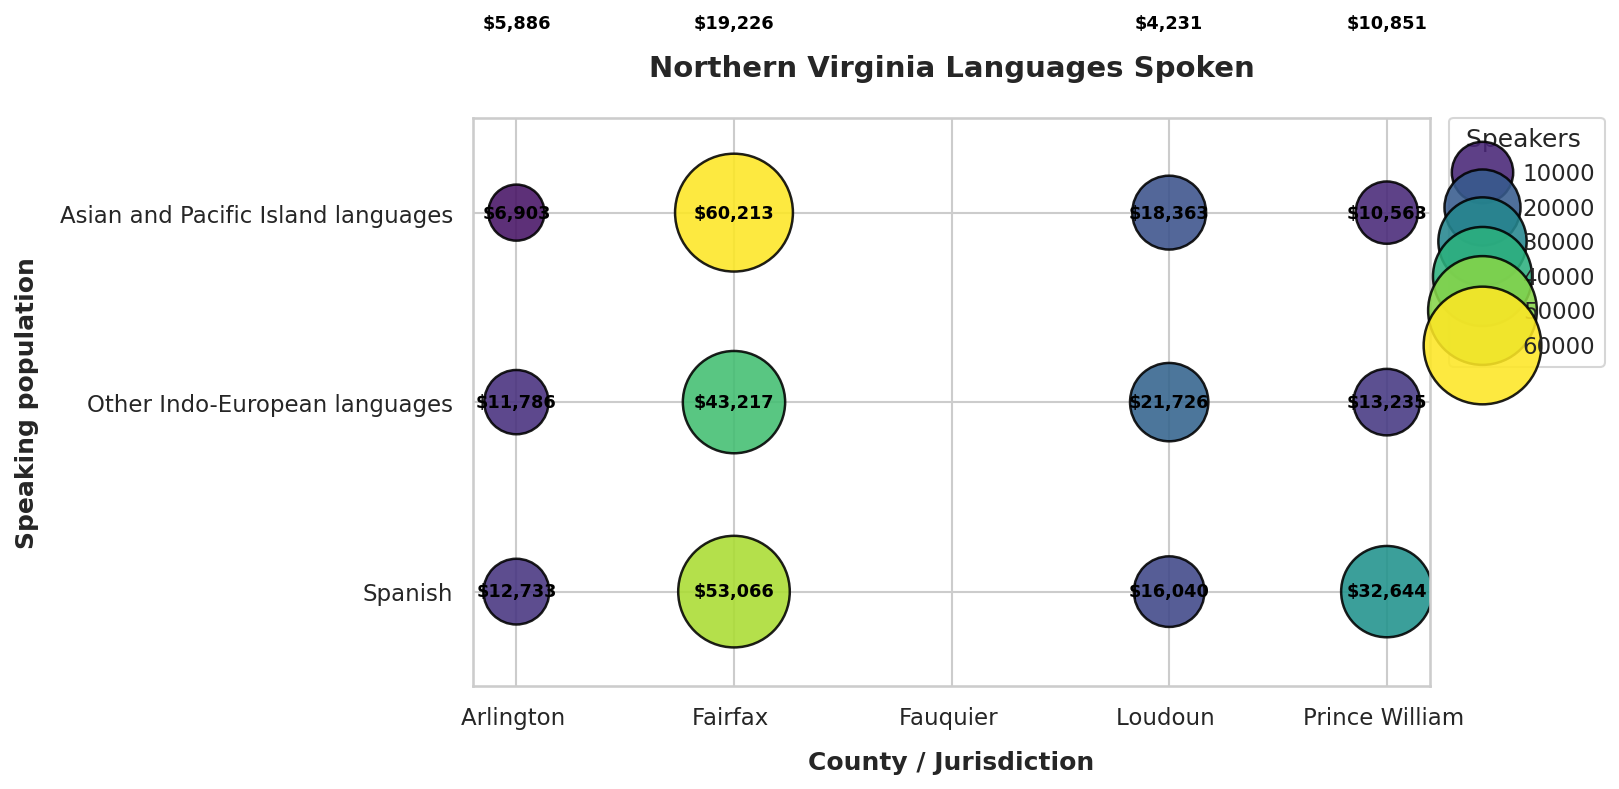

In [117]:
# Plot

sns.set_theme(style="whitegrid")
fig,ax = plt.subplots(figsize = (11,5.5),dpi = 150)

scatter = sns.scatterplot(
    data = df_speaking_language_clean_var,
    x = "Region",
    y = "Languages",
    size = "Speakers",
    hue = "Speakers",
    palette = "viridis",
    sizes = (600,3200),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.88,
    ax=ax,
)

# Add the exact Speakers in each bubble

for _,row in df_speaking_language_clean_var.iterrows():
  if pd.notna(row["Speakers"]):
    ax.text(
        x = row["Region"],
        y = row["Languages"],
        s = f"${int(row["Speakers"]):,}",
        ha="center",
              va="center",
              fontsize=8.5,
              fontweight="bold",
              color="black",
  )

# Polish Titles and Axes
plt.title(
    "Northern Virginia Languages Spoken",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("County / Jurisdiction", fontweight="bold", labelpad=10)
plt.ylabel("Speaking population", fontweight="bold", labelpad=10)
ax.set_ylim(-0.5, 2.5)  # Add breathing room for top and bottom bubbles

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    title="Speakers ",
)

plt.tight_layout()
plt.show()